# S3 data usage exploration

Explores the `weekly_report` Storage Lens table (one row per S3 prefix, ~2.8M rows) to see which data types use the most storage.

**All the analysis logic lives in `s3_data_use.py`** so it can be reused elsewhere (e.g. a Flask portal). This notebook only imports those functions and calls them; edit the module, not the notebook, to change behavior.

## Running this notebook

Pick the project `.venv` as the kernel (Select Kernel -> Jupyter Kernel -> "S3 data use exploration (.venv)"). Credentials are only needed to *refresh* the cached data; the cells below read the cached `weekly_report.parquet` and `capsule_map.json`, so they run offline.

To refresh from source: run `aws sso login --profile aind_prod_sso`, then `s3.load_weekly_report(use_cache=False)` (re-queries the RDS table), and `resolve_capsules.py` (rebuilds `capsule_map.json`, needs the Code Ocean token).

In [1]:
import pandas as pd

import s3_data_use as s3

pd.set_option("display.max_columns", None)     # show every column
pd.set_option("display.max_colwidth", None)    # never truncate cell values (full asset names)
pd.set_option("display.width", None)           # don't wrap on terminal width
pd.options.display.float_format = "{:,.2f}".format

# Load the cached snapshot and attach the data-type `category` column.
df = s3.load_weekly_report()      # reads weekly_report.parquet (use_cache=False re-queries RDS)
df = s3.add_category(df)          # reads capsule_map.json to resolve Code Ocean pipelines
print(f"{len(df):,} prefixes, {df['size_tb'].sum():,.0f} TB, {df['category'].nunique()} categories")

2,817,972 prefixes, 30,104 TB, 224 categories


## DocDB project names (v1 and v2)

For every asset name (`prefix`), look up its project in DocDB **v1** and **v2** and attach four columns to `df`: `exists_in_v1`, `v1_project_name`, `exists_in_v2`, `v2_project_name` (project = `data_description.project_name`). A name absent from a version gets `exists_*=False` and a null project. Cached to `docdb_project_map.parquet` (the query is ~1 min for ~142k names).

Note: this looks up by asset **name**, so UUID-named Code Ocean prefixes (which DocDB keys by id, not name) won't match and will show `False`. Compare these against the `project_name` column from the weekly_report table to find where they disagree.

In [2]:
import time
from pathlib import Path

from aind_data_access_api.document_db import MetadataDbClient

DOCDB_HOST = "api.allenneuraldynamics.org"
DOCDB_MAP = Path("docdb_project_map.parquet")
_PROJ = {"_id": 0, "name": 1, "data_description.project_name": 1}
_CHUNK = 250


def _docdb_project_map(version, names):
    """{name: project_name-or-None} for names present in this DocDB version."""
    client = MetadataDbClient(host=DOCDB_HOST, version=version)
    out = {}
    for i in range(0, len(names), _CHUNK):
        chunk = names[i:i + _CHUNK]
        for attempt in range(4):
            try:
                recs = client.fetch_records_by_filter_list("name", chunk, projection=_PROJ)
                break
            except Exception:
                if attempt == 3:
                    raise
                time.sleep(2 ** attempt)
        for r in recs:
            nm = r.get("name")
            if nm not in out:                       # first record for a name wins
                out[nm] = (r.get("data_description") or {}).get("project_name")
    return out


if DOCDB_MAP.exists():
    dmap = pd.read_parquet(DOCDB_MAP)
    print(f"Loaded DocDB project map from cache: {len(dmap):,} names")
else:
    names = df["prefix"].dropna().unique().tolist()
    print(f"Querying DocDB v1 + v2 by name for {len(names):,} assets (~1 min)...")
    v2 = _docdb_project_map("v2", names)
    v1 = _docdb_project_map("v1", names)
    dmap = pd.DataFrame({"name": names})
    dmap["exists_in_v1"] = dmap["name"].isin(v1)
    dmap["v1_project_name"] = dmap["name"].map(v1)
    dmap["exists_in_v2"] = dmap["name"].isin(v2)
    dmap["v2_project_name"] = dmap["name"].map(v2)
    dmap.to_parquet(DOCDB_MAP)
    print(f"v1 hits {dmap['exists_in_v1'].sum():,} | v2 hits {dmap['exists_in_v2'].sum():,}; cached to {DOCDB_MAP}")

# Attach the four columns to df, keyed on asset name (prefix). Idempotent re-run.
_new = ["exists_in_v1", "v1_project_name", "exists_in_v2", "v2_project_name"]
df = df.drop(columns=[c for c in _new + ["name"] if c in df.columns])
df = df.merge(dmap, how="left", left_on="prefix", right_on="name").drop(columns="name")
df["exists_in_v1"] = df["exists_in_v1"].fillna(False)
df["exists_in_v2"] = df["exists_in_v2"].fillna(False)
print("added columns:", _new)
df[["prefix"] + _new].drop_duplicates("prefix").head()

Loaded DocDB project map from cache: 142,032 names


added columns: ['exists_in_v1', 'v1_project_name', 'exists_in_v2', 'v2_project_name']


,prefix,exists_in_v1,v1_project_name,exists_in_v2,v2_project_name
0,c8b5ad22-b8eb-4f02-809b-be56178ec35a,False,NaN,False,NaN
1,17d1044b-6653-49df-b2f1-bdb53a10542f,False,NaN,False,NaN
2,6666b56b-440b-4bf5-9b19-dc2601f97d73,False,NaN,False,NaN
3,c84eb3f5-3d33-41f5-b33c-1fa8464000f6,False,NaN,False,NaN
4,e690b0ce-0839-4c87-9767-22df5dc8beec,False,NaN,False,NaN


### Derived project-name comparison flags

Boolean columns comparing the weekly_report `project_name` against DocDB:

- `exists_in_docdb` — in v1 or v2 (False only if absent from both)
- `has_project_name_in_table` — weekly_report `project_name` is set (non-null, not "unknown")
- `has_project_name_in_docdb` — v1 or v2 has a project (non-null, not "unknown")
- `unexplained_missing_project_name_in_table` — the table is missing a project that DocDB has (the gap we found)

In [34]:
def _has_project(s):
    """True where a project string is set (non-null and not 'unknown')."""
    s = s.astype("string")
    return (s.notna() & (s.str.lower() != "unknown")).fillna(False).astype(bool)

df["exists_in_docdb"] = df["exists_in_v1"] | df["exists_in_v2"]
df["has_project_name_in_table"] = _has_project(df["project_name"])
df["has_project_name_in_docdb"] = _has_project(df["v1_project_name"]) | _has_project(df["v2_project_name"])
df["unexplained_missing_project_name_in_table"] = (
    ~df["has_project_name_in_table"] & df["has_project_name_in_docdb"]
)

n = df.loc[df["unexplained_missing_project_name_in_table"], "prefix"].nunique()
print(f"assets with unexplained missing project (in DocDB, null in table): {n:,}")
df[["prefix", "exists_in_docdb", "has_project_name_in_table",
    "has_project_name_in_docdb", "unexplained_missing_project_name_in_table"]].drop_duplicates("prefix").head()

assets with unexplained missing project (in DocDB, null in table): 2,342


,prefix,exists_in_docdb,has_project_name_in_table,has_project_name_in_docdb,unexplained_missing_project_name_in_table
0,c8b5ad22-b8eb-4f02-809b-be56178ec35a,False,True,False,False
1,17d1044b-6653-49df-b2f1-bdb53a10542f,False,False,False,False
2,6666b56b-440b-4bf5-9b19-dc2601f97d73,False,False,False,False
3,c84eb3f5-3d33-41f5-b33c-1fa8464000f6,False,False,False,False
4,e690b0ce-0839-4c87-9767-22df5dc8beec,False,False,False,False


In [35]:
df.sample(10)

,prefix,bucket,subprefix,storage_class,intelligent_tiering_access_tier,size_in_bytes,number_of_files,project_name,report_date,size_tb,size_gb,category,exists_in_v1,v1_project_name,exists_in_v2,v2_project_name,exists_in_docdb,has_project_name_in_table,has_project_name_in_docdb,unexplained_missing_project_name_in_table
1025744,00b268b1-8f1c-418c-8d92-cec7fe21f283,codeocean-s3datasetsbucket-1u41qdg42ur9,00b268b1-8f1c-418c-8d92-cec7fe21f283/3.2.2,INTELLIGENT_TIERING,ARCHIVE_INSTANT_ACCESS,677194,1,<NA>,2026-06-28T01-00Z,0.00,0.00,codeocean-dataset (unresolved),False,NaN,False,NaN,False,False,False,False
1340289,832049_2025-12-17_15-42-05,aind-open-data,832049_2025-12-17_15-42-05/behavior-videos,STANDARD,<NA>,306,2,Single-neuron computations within brain-wide circuits (SCBC) - SLAP2,2026-06-28T01-00Z,0.00,0.00,aind-open-data (uuid),False,NaN,True,Single-neuron computations within brain-wide circuits (SCBC) - SLAP2,True,True,True,False
1342761,single-plane-ophys_820614_2026-06-01_11-30-59,aind-open-data,single-plane-ophys_820614_2026-06-01_11-30-59/original_metadata,STANDARD,<NA>,44273,6,Brain Computer Interface,2026-06-28T01-00Z,0.00,0.00,single-plane-ophys,True,Brain Computer Interface,True,Brain Computer Interface,True,True,True,False
1881465,foraging_nwb_bonsai_processed,aind-behavior-data,foraging_nwb_bonsai_processed/782226_2025-04-25_182740,INTELLIGENT_TIERING,FREQUENT,512220,2,<NA>,2026-06-28T01-00Z,0.00,0.00,behavior,False,NaN,False,NaN,False,False,False,False
2032889,behavior_625918_2022-07-01_16-43-13,aind-private-data-prod-o5171v,behavior_625918_2022-07-01_16-43-13/rig.json,STANDARD,<NA>,4951,1,Dynamic Routing,2026-06-28T01-00Z,0.00,0.00,behavior,True,Dynamic Routing,True,Dynamic Routing,True,True,True,False
1433615,behavior_816214_2026-01-08_14-57-04_processed_2026-02-19_13-09-24,aind-open-data,behavior_816214_2026-01-08_14-57-04_processed_2026-02-19_13-09-24/data_description.json,STANDARD,<NA>,3339,1,Discovery-Neuromodulator circuit dynamics during foraging - Subproject 3 Fiber Photometry Recordings of NM Release During Behavior,2026-06-28T01-00Z,0.00,0.00,behavior,True,Discovery-Neuromodulator circuit dynamics during foraging - Subproject 3 Fiber Photometry Recordings of NM Release During Behavior,True,Discovery-Neuromodulator circuit dynamics during foraging - Subproject 3 Fiber Photometry Recordings of NM Release During Behavior,True,True,True,False
2040210,behavior_781471_2025-03-12_13-14-54,aind-private-data-prod-o5171v,behavior_781471_2025-03-12_13-14-54/subject.json,STANDARD,<NA>,950,1,Behavior Platform,2026-06-28T01-00Z,0.00,0.00,behavior,True,Behavior Platform,True,Behavior Platform,True,True,True,False
546332,8ad617b1-3324-4a22-b64a-9b6f0fa53e37,codeocean-s3datasetsbucket-1u41qdg42ur9,8ad617b1-3324-4a22-b64a-9b6f0fa53e37/0.0.2.85.28,STANDARD,<NA>,94423,1,<NA>,2026-06-28T01-00Z,0.00,0.00,codeocean-dataset (unresolved),False,NaN,False,NaN,False,False,False,False
1830778,behavior_781895_2025-07-02_13-23-00,aind-open-data,behavior_781895_2025-07-02_13-23-00/session.json,STANDARD,<NA>,18214,1,Discovery-Neuromodulator circuit dynamics during foraging - Subproject 3 Fiber Photometry Recordings of NM Release During Behavior,2026-06-28T01-00Z,0.00,0.00,behavior,True,Discovery-Neuromodulator circuit dynamics during foraging - Subproject 3 Fiber Photometry Recordings of NM Release During Behavior,True,Discovery-Neuromodulator circuit dynamics during foraging - Subproject 3 Fiber Photometry Recordings of NM Release During Behavior,True,True,True,False
372466,04534fce-7e3a-4163-82c0-edf7f6b8852c,codeocean-s3datasetsbucket-1u41qdg42ur9,04534fce-7e3a-4163-82c0-edf7f6b8852c/697926_2024-02-22_133255,STANDARD,<NA>,5793,1,<NA>,2026-06-28T01-00Z,0.00,0.00,codeocean-dataset (unresolved),False,NaN,False,NaN,False,False,False,False


In [36]:
df.query("prefix == 'HCR_831990-s6-r2_2026-06-23_00-00-06_processed_2026-06-25_02-40-05'")

,prefix,bucket,subprefix,storage_class,intelligent_tiering_access_tier,size_in_bytes,number_of_files,project_name,report_date,size_tb,size_gb,category,exists_in_v1,v1_project_name,exists_in_v2,v2_project_name,exists_in_docdb,has_project_name_in_table,has_project_name_in_docdb,unexplained_missing_project_name_in_table
1330898,HCR_831990-s6-r2_2026-06-23_00-00-06_processed_2026-06-25_02-40-05,aind-open-data,HCR_831990-s6-r2_2026-06-23_00-00-06_processed_2026-06-25_02-40-05/data_description.json,STANDARD,<NA>,1811,1,<NA>,2026-06-28T01-00Z,0.00,0.00,HCR,True,PLACE,True,PLACE,True,False,True,True
1339867,HCR_831990-s6-r2_2026-06-23_00-00-06_processed_2026-06-25_02-40-05,aind-open-data,HCR_831990-s6-r2_2026-06-23_00-00-06_processed_2026-06-25_02-40-05/image_cross_image_alignment,STANDARD,<NA>,572595,64,<NA>,2026-06-28T01-00Z,0.00,0.00,HCR,True,PLACE,True,PLACE,True,False,True,True
1401688,HCR_831990-s6-r2_2026-06-23_00-00-06_processed_2026-06-25_02-40-05,aind-open-data,HCR_831990-s6-r2_2026-06-23_00-00-06_processed_2026-06-25_02-40-05/image_radial_correction,INTELLIGENT_TIERING,FREQUENT,7164725572440,4470581,<NA>,2026-06-28T01-00Z,7.16,"7,164.73",HCR,True,PLACE,True,PLACE,True,False,True,True
1409909,HCR_831990-s6-r2_2026-06-23_00-00-06_processed_2026-06-25_02-40-05,aind-open-data,HCR_831990-s6-r2_2026-06-23_00-00-06_processed_2026-06-25_02-40-05/instrument.json,STANDARD,<NA>,20028,1,<NA>,2026-06-28T01-00Z,0.00,0.00,HCR,True,PLACE,True,PLACE,True,False,True,True
1425564,HCR_831990-s6-r2_2026-06-23_00-00-06_processed_2026-06-25_02-40-05,aind-open-data,HCR_831990-s6-r2_2026-06-23_00-00-06_processed_2026-06-25_02-40-05/image_cross_image_alignment,INTELLIGENT_TIERING,FREQUENT,3316572,2,<NA>,2026-06-28T01-00Z,0.00,0.00,HCR,True,PLACE,True,PLACE,True,False,True,True
1443223,HCR_831990-s6-r2_2026-06-23_00-00-06_processed_2026-06-25_02-40-05,aind-open-data,HCR_831990-s6-r2_2026-06-23_00-00-06_processed_2026-06-25_02-40-05/image_tile_alignment,INTELLIGENT_TIERING,FREQUENT,42693318,17,<NA>,2026-06-28T01-00Z,0.00,0.04,HCR,True,PLACE,True,PLACE,True,False,True,True
1448811,HCR_831990-s6-r2_2026-06-23_00-00-06_processed_2026-06-25_02-40-05,aind-open-data,HCR_831990-s6-r2_2026-06-23_00-00-06_processed_2026-06-25_02-40-05/image_radial_correction,STANDARD,<NA>,18893423,8612,<NA>,2026-06-28T01-00Z,0.00,0.02,HCR,True,PLACE,True,PLACE,True,False,True,True
1454396,HCR_831990-s6-r2_2026-06-23_00-00-06_processed_2026-06-25_02-40-05,aind-open-data,HCR_831990-s6-r2_2026-06-23_00-00-06_processed_2026-06-25_02-40-05/camera_aligned_neuroglancer.json,INTELLIGENT_TIERING,FREQUENT,2742044,1,<NA>,2026-06-28T01-00Z,0.00,0.00,HCR,True,PLACE,True,PLACE,True,False,True,True
1486647,HCR_831990-s6-r2_2026-06-23_00-00-06_processed_2026-06-25_02-40-05,aind-open-data,HCR_831990-s6-r2_2026-06-23_00-00-06_processed_2026-06-25_02-40-05/procedures.json,STANDARD,<NA>,1756,1,<NA>,2026-06-28T01-00Z,0.00,0.00,HCR,True,PLACE,True,PLACE,True,False,True,True
1493545,HCR_831990-s6-r2_2026-06-23_00-00-06_processed_2026-06-25_02-40-05,aind-open-data,HCR_831990-s6-r2_2026-06-23_00-00-06_processed_2026-06-25_02-40-05/original_metadata,INTELLIGENT_TIERING,FREQUENT,1537584,1,<NA>,2026-06-28T01-00Z,0.00,0.00,HCR,True,PLACE,True,PLACE,True,False,True,True


In [37]:
#add cell with query for missing project name from both v1 and v2 and sort by dates in the last month

# aind-open-data assets whose project is missing in BOTH DocDB v1 and v2, one row per
# asset (group by prefix), sessions from the last month, most recent first.
asset = (
    df[df["bucket"] == "aind-open-data"]
    .groupby("prefix", as_index=False)
    .agg(size_tb=("size_tb", "sum"),
         exists_in_v1=("exists_in_v1", "first"),
         exists_in_v2=("exists_in_v2", "first"),
         v1_project_name=("v1_project_name", "first"),
         v2_project_name=("v2_project_name", "first"))
)
asset["date"] = pd.to_datetime(
    asset["prefix"].str.extract(r"(\d{4}-\d{2}-\d{2})_\d{2}-\d{2}-\d{2}")[0], errors="coerce")

missing_both = asset["v1_project_name"].isna() & asset["v2_project_name"].isna()
last_month = asset["date"] >= asset["date"].max() - pd.Timedelta(days=30)

missing_project = (
    asset[missing_both & last_month]
    .sort_values("date", ascending=False)[
        ["prefix", "size_tb", "date", "exists_in_v1", "exists_in_v2"]
    ]
    .reset_index(drop=True)
)
print(f"{len(missing_project)} aind-open-data assets missing project in BOTH v1 and v2 (last month)")
missing_project

41 aind-open-data assets missing project in BOTH v1 and v2 (last month)


,prefix,size_tb,date,exists_in_v1,exists_in_v2
0,single-plane-ophys_820615_2026-06-26_11-00-41,0.02,2026-06-26,False,False
1,HCR_804363_roi-shape-metrics_2026-06-25_21-31-46,0.00,2026-06-25,False,False
2,HCR_800995_roi-shape-metrics_2026-06-25_21-31-41,0.00,2026-06-25,False,False
3,single-plane-ophys_820615_2026-06-23_14-16-29,0.06,2026-06-23,False,False
4,exaSPIM_734738_2026-06-12_18-02-14_processed_2026-06-22_17-34-02,34.35,2026-06-12,False,False
5,exaSPIM_734738_2026-06-12_18-02-14_processed_2026-06-22_12-01-38,16.62,2026-06-12,False,False
6,exaSPIM_734738_2026-06-12_18-02-14,43.56,2026-06-12,False,False
7,exaSPIM_791116_2026-06-09_16-31-33_processed_2026-06-16_12-28-34,38.70,2026-06-09,False,False
8,exaSPIM_791116_2026-06-09_16-31-33,32.61,2026-06-09,False,False
9,exaSPIM_709220_2026-06-09_18-28-35_processed_2026-06-22_14-05-16,17.09,2026-06-09,False,False


In [38]:
df.query("unexplained_missing_project_name_in_table").sample(20)

,prefix,bucket,subprefix,storage_class,intelligent_tiering_access_tier,size_in_bytes,number_of_files,project_name,report_date,size_tb,size_gb,category,exists_in_v1,v1_project_name,exists_in_v2,v2_project_name,exists_in_docdb,has_project_name_in_table,has_project_name_in_docdb,unexplained_missing_project_name_in_table
1596678,HCR_000000-s40_2025-07-11_13-00-00_processed_2025-09-03_16-48-27,aind-open-data,HCR_000000-s40_2025-07-11_13-00-00_processed_2025-09-03_16-48-27/original_metadata,STANDARD,<NA>,118593,6,<NA>,2026-06-28T01-00Z,0.00,0.00,HCR,True,Learning mFISH-V1omFISH,False,NaN,True,False,True,True
2177039,behavior_766998_2025-04-09_19-06-51,aind-private-data-prod-o5171v,behavior_766998_2025-04-09_19-06-51/behavior,INTELLIGENT_TIERING,ARCHIVE_INSTANT_ACCESS,141142041,5,<NA>,2026-06-28T01-00Z,0.00,0.14,behavior,True,AIND Viral Genetic Tools,False,NaN,True,False,True,True
1644672,behavior_810434_2025-08-15_20-38-34,aind-open-data,behavior_810434_2025-08-15_20-38-34/behavior,INTELLIGENT_TIERING,FREQUENT,11702152,2,<NA>,2026-06-28T01-00Z,0.00,0.01,behavior,True,Genetic Perturbation Platform,False,NaN,True,False,True,True
1557780,exaSPIM_709221_2025-05-16_12-00-49_processed_2026-03-06_11-16-33,aind-open-data,exaSPIM_709221_2025-05-16_12-00-49_processed_2026-03-06_11-16-33/metadata.nd.json,STANDARD,<NA>,69490,1,<NA>,2026-06-28T01-00Z,0.00,0.00,exaSPIM,True,MSMA Platform,False,NaN,True,False,True,True
1330728,behavior_770777_2025-06-27_19-54-45,aind-open-data,behavior_770777_2025-06-27_19-54-45/session.json,STANDARD,<NA>,7801,1,<NA>,2026-06-28T01-00Z,0.00,0.00,behavior,True,Genetic Perturbation Platform,False,NaN,True,False,True,True
1632948,SmartSPIM_656425_2023-04-06_16-55-38,aind-open-data,SmartSPIM_656425_2023-04-06_16-55-38/acquisition.json,STANDARD,<NA>,67287,1,<NA>,2026-06-28T01-00Z,0.00,0.00,SmartSPIM,True,CTY Genetic Tools,False,NaN,True,False,True,True
1615406,behavior_781575_2025-07-08_21-29-35,aind-open-data,behavior_781575_2025-07-08_21-29-35/behavior-videos,INTELLIGENT_TIERING,INFREQUENT,14988703904,2,<NA>,2026-06-28T01-00Z,0.01,14.99,behavior,True,Genetic Perturbation Platform,False,NaN,True,False,True,True
1966317,behavior_711069_2024-05-29_14-44-15,aind-private-data-prod-o5171v,behavior_711069_2024-05-29_14-44-15/metadata.nd.json,STANDARD,<NA>,51421,1,<NA>,2026-06-28T01-00Z,0.00,0.00,behavior,True,Discovery-Neuromodulator circuit dynamics during foraging,False,NaN,True,False,True,True
1627381,behavior_814147_2025-10-30_16-24-19_processed_2025-10-31_05-35-19,aind-open-data,behavior_814147_2025-10-30_16-24-19_processed_2025-10-31_05-35-19/dynamic-foraging-qc,STANDARD,<NA>,56302,1,<NA>,2026-06-28T01-00Z,0.00,0.00,behavior,True,Genetic Perturbation Platform,False,NaN,True,False,True,True
1692128,behavior_818909_2026-01-13_20-18-00,aind-open-data,behavior_818909_2026-01-13_20-18-00/fib,INTELLIGENT_TIERING,ARCHIVE_INSTANT_ACCESS,18026400000,3,<NA>,2026-06-28T01-00Z,0.02,18.03,behavior,True,Genetic Perturbation Platform,False,NaN,True,False,True,True


## Size by bucket

In [39]:
df.query("prefix == 'behavior_766998_2025-04-09_19-06-51'")

,prefix,bucket,subprefix,storage_class,intelligent_tiering_access_tier,size_in_bytes,number_of_files,project_name,report_date,size_tb,size_gb,category,exists_in_v1,v1_project_name,exists_in_v2,v2_project_name,exists_in_docdb,has_project_name_in_table,has_project_name_in_docdb,unexplained_missing_project_name_in_table
1948381,behavior_766998_2025-04-09_19-06-51,aind-private-data-prod-o5171v,behavior_766998_2025-04-09_19-06-51/original_metadata,STANDARD,<NA>,49202,6,<NA>,2026-06-28T01-00Z,0.00,0.00,behavior,True,AIND Viral Genetic Tools,False,NaN,True,False,True,True
1952628,behavior_766998_2025-04-09_19-06-51,aind-private-data-prod-o5171v,behavior_766998_2025-04-09_19-06-51/metadata.nd.json,STANDARD,<NA>,54673,1,<NA>,2026-06-28T01-00Z,0.00,0.00,behavior,True,AIND Viral Genetic Tools,False,NaN,True,False,True,True
1962334,behavior_766998_2025-04-09_19-06-51,aind-private-data-prod-o5171v,behavior_766998_2025-04-09_19-06-51/session.json,STANDARD,<NA>,7816,1,<NA>,2026-06-28T01-00Z,0.00,0.00,behavior,True,AIND Viral Genetic Tools,False,NaN,True,False,True,True
1969555,behavior_766998_2025-04-09_19-06-51,aind-private-data-prod-o5171v,behavior_766998_2025-04-09_19-06-51/fib,STANDARD,<NA>,3757,2,<NA>,2026-06-28T01-00Z,0.00,0.00,behavior,True,AIND Viral Genetic Tools,False,NaN,True,False,True,True
1972250,behavior_766998_2025-04-09_19-06-51,aind-private-data-prod-o5171v,behavior_766998_2025-04-09_19-06-51/processing.json,STANDARD,<NA>,405,1,<NA>,2026-06-28T01-00Z,0.00,0.00,behavior,True,AIND Viral Genetic Tools,False,NaN,True,False,True,True
1975504,behavior_766998_2025-04-09_19-06-51,aind-private-data-prod-o5171v,behavior_766998_2025-04-09_19-06-51/fib,INTELLIGENT_TIERING,ARCHIVE_INSTANT_ACCESS,24566400000,3,<NA>,2026-06-28T01-00Z,0.02,24.57,behavior,True,AIND Viral Genetic Tools,False,NaN,True,False,True,True
1977229,behavior_766998_2025-04-09_19-06-51,aind-private-data-prod-o5171v,behavior_766998_2025-04-09_19-06-51/behavior,STANDARD,<NA>,496407,46,<NA>,2026-06-28T01-00Z,0.00,0.00,behavior,True,AIND Viral Genetic Tools,False,NaN,True,False,True,True
2006863,behavior_766998_2025-04-09_19-06-51,aind-private-data-prod-o5171v,behavior_766998_2025-04-09_19-06-51/behavior-videos,INTELLIGENT_TIERING,ARCHIVE_INSTANT_ACCESS,58926499442,4,<NA>,2026-06-28T01-00Z,0.06,58.93,behavior,True,AIND Viral Genetic Tools,False,NaN,True,False,True,True
2029210,behavior_766998_2025-04-09_19-06-51,aind-private-data-prod-o5171v,behavior_766998_2025-04-09_19-06-51/data_description.json,STANDARD,<NA>,1703,1,<NA>,2026-06-28T01-00Z,0.00,0.00,behavior,True,AIND Viral Genetic Tools,False,NaN,True,False,True,True
2041873,behavior_766998_2025-04-09_19-06-51,aind-private-data-prod-o5171v,behavior_766998_2025-04-09_19-06-51/subject.json,STANDARD,<NA>,1300,1,<NA>,2026-06-28T01-00Z,0.00,0.00,behavior,True,AIND Viral Genetic Tools,False,NaN,True,False,True,True


In [40]:
df.size

56359440

In [42]:
df.to_parquet("/Users/doug.ollerenshaw/2026.07.14_s3_data_use_exploration_report_with_docdb.parquet")

In [7]:
s3.size_by_bucket(df)

,total_tb
bucket,
aind-open-data,"20,304.71"
codeocean-s3resultsbucket-1182nktl2bh9f,"3,497.47"
aind-archive,"1,846.75"
codeocean-s3datasetsbucket-1u41qdg42ur9,"1,772.62"
aind-scratch-data,"1,365.67"
codeocean-s3batchbucket-16itpvq060udk,575.73
aind-private-data-prod-o5171v,549.61
aind-msma-morphology-data,91.02
aind-ephys-data,49.96


## Size by category

A category is a data-type/modality label assigned to every prefix. See the `s3_data_use` module docstring for how each prefix is labeled (named-prefix token, resolved Code Ocean pipeline, or bucket fallback), and `s3.MODALITY_RULES` for the keyword map you can edit.

In [8]:
s3.size_by_category(df)

,total_tb,n_prefixes
category,,
exaSPIM,"10,247.88",973
SmartSPIM,"7,292.19",9208
multiplane-ophys,"1,571.09",3941
codeocean-pipeline (private/unresolved),"1,391.67",959
HCR,"1,296.27",3143
codeocean-dataset (unresolved),"1,045.44",48569
timwang,"1,024.58",1
behavior,703.36,35777
rachel.dalley,644.79,1


## Category by bucket (main view)

TB by category (rows) x bucket (columns). Bucket columns are ordered by total size (largest, `aind-open-data`, on the left); category rows are sorted by `aind-open-data` usage. The bottom `TOTAL` row is the true per-bucket size and the `(other categories)` row rolls up everything below the top 20, so every column adds up. Pass `sort_bucket=`, `top_n=`, or `round_tb=` to customize.

In [9]:
s3.category_by_bucket(df, sort_bucket="aind-open-data")

bucket,aind-open-data,codeocean-s3resultsbucket-1182nktl2bh9f,aind-archive,codeocean-s3datasetsbucket-1u41qdg42ur9,aind-scratch-data,codeocean-s3batchbucket-16itpvq060udk,aind-private-data-prod-o5171v,aind-msma-morphology-data,aind-ephys-data,aind-ophys-data,aind-behavior-data,aind-private-scratch-data-prod-o5171v,aind-open-data-prod-o5171v,TOTAL
category,,,,,,,,,,,,,,
exaSPIM,"10,153.74",24.29,0.00,0.00,68.24,1.56,0.00,0.06,0.00,0.00,0.00,0.00,0.00,"10,247.88"
SmartSPIM,"6,690.47",54.03,0.00,0.00,129.08,416.05,0.58,0.00,0.00,0.00,0.00,0.00,1.98,"7,292.19"
HCR,"1,271.97",21.15,0.00,0.00,2.65,0.50,0.00,0.00,0.00,0.00,0.00,0.00,0.00,"1,296.27"
other categories,483.45,0.00,0.00,0.00,9.67,0.00,0.53,0.00,0.00,0.00,0.00,0.00,0.00,493.65
multiplane-ophys,463.88,"1,005.76",0.00,0.00,0.02,1.03,100.40,0.00,0.00,0.00,0.00,0.00,0.00,"1,571.09"
behavior,405.81,58.89,3.30,0.00,38.88,0.03,195.43,0.00,0.00,0.00,1.03,0.00,0.00,703.36
fMOST,280.14,0.00,0.00,0.00,0.00,0.00,0.00,20.46,0.00,0.00,0.00,0.00,0.00,300.60
ecephys,215.81,77.68,0.06,0.00,0.76,85.56,167.10,0.00,49.95,0.00,0.00,0.00,0.00,596.92
single-plane-ophys,49.00,57.84,0.00,0.00,1.58,0.00,70.77,0.00,0.00,0.19,0.00,0.00,0.00,179.38


## One call for an app (e.g. Dan's Flask portal)

`build_category_by_bucket()` does load -> add category -> pivot in one shot from the cached artifacts (no AWS/Code Ocean credentials needed) and returns a DataFrame. A Flask view can render it directly with `.to_html(...)`.

In [10]:
table = s3.build_category_by_bucket(sort_bucket="aind-open-data")

# In a Flask view this is what you'd hand to the template:
html = table.to_html(classes="table table-sm", border=0, float_format=lambda x: f"{x:,.1f}")
print(html[:400], "...")
table

<table class="dataframe table table-sm">
  <thead>
    <tr style="text-align: right;">
      <th>bucket</th>
      <th>aind-open-data</th>
      <th>codeocean-s3resultsbucket-1182nktl2bh9f</th>
      <th>aind-archive</th>
      <th>codeocean-s3datasetsbucket-1u41qdg42ur9</th>
      <th>aind-scratch-data</th>
      <th>codeocean-s3batchbucket-16itpvq060udk</th>
      <th>aind-private-data-prod-o517 ...


bucket,aind-open-data,codeocean-s3resultsbucket-1182nktl2bh9f,aind-archive,codeocean-s3datasetsbucket-1u41qdg42ur9,aind-scratch-data,codeocean-s3batchbucket-16itpvq060udk,aind-private-data-prod-o5171v,aind-msma-morphology-data,aind-ephys-data,aind-ophys-data,aind-behavior-data,aind-private-scratch-data-prod-o5171v,aind-open-data-prod-o5171v,TOTAL
category,,,,,,,,,,,,,,
exaSPIM,"10,153.74",24.29,0.00,0.00,68.24,1.56,0.00,0.06,0.00,0.00,0.00,0.00,0.00,"10,247.88"
SmartSPIM,"6,690.47",54.03,0.00,0.00,129.08,416.05,0.58,0.00,0.00,0.00,0.00,0.00,1.98,"7,292.19"
HCR,"1,271.97",21.15,0.00,0.00,2.65,0.50,0.00,0.00,0.00,0.00,0.00,0.00,0.00,"1,296.27"
other categories,483.45,0.00,0.00,0.00,9.67,0.00,0.53,0.00,0.00,0.00,0.00,0.00,0.00,493.65
multiplane-ophys,463.88,"1,005.76",0.00,0.00,0.02,1.03,100.40,0.00,0.00,0.00,0.00,0.00,0.00,"1,571.09"
behavior,405.81,58.89,3.30,0.00,38.88,0.03,195.43,0.00,0.00,0.00,1.03,0.00,0.00,703.36
fMOST,280.14,0.00,0.00,0.00,0.00,0.00,0.00,20.46,0.00,0.00,0.00,0.00,0.00,300.60
ecephys,215.81,77.68,0.06,0.00,0.76,85.56,167.10,0.00,49.95,0.00,0.00,0.00,0.00,596.92
single-plane-ophys,49.00,57.84,0.00,0.00,1.58,0.00,70.77,0.00,0.00,0.19,0.00,0.00,0.00,179.38


## Reprocessing waste (aind-open-data)

How much storage is held by **superseded reprocessing runs**. A derived asset name parses into `(raw source, process, run datetime)` (schema convention `{raw_input}_{process}_{datetime}`). For each `(raw asset, process)` we keep only the **latest** run and count every older run as reclaimable. All of this comes from names + sizes in the inventory, computed by `s3_data_use` (`reprocessing_table`, `build_reprocessing_report`), so it needs no extra credentials and is reusable by an app.

In [11]:
rep = s3.reprocessing_table(df, bucket="aind-open-data")   # analysis is aind-open-data only
s3.reprocessing_summary(rep).to_frame("value")

,value
derived_assets,"14,297.00"
derived_tb,"9,177.60"
raw+process_groups,"9,396.00"
groups_reprocessed,"2,788.00"
pct_groups_reprocessed,29.70
redundant_runs,"4,901.00"
raw_assets_affected,"2,676.00"
reclaimable_tb,"2,440.30"


### Redundant reprocessing: by modality and by rerun count

Left: redundant reprocessing (TB) by modality (the `(unlabeled)` subject-only names are excluded). Right: how many `(raw asset, process)` groups were run 2, 3, ... times (the long tail past 10 is pooled into `11+`). Both are horizontal bars.

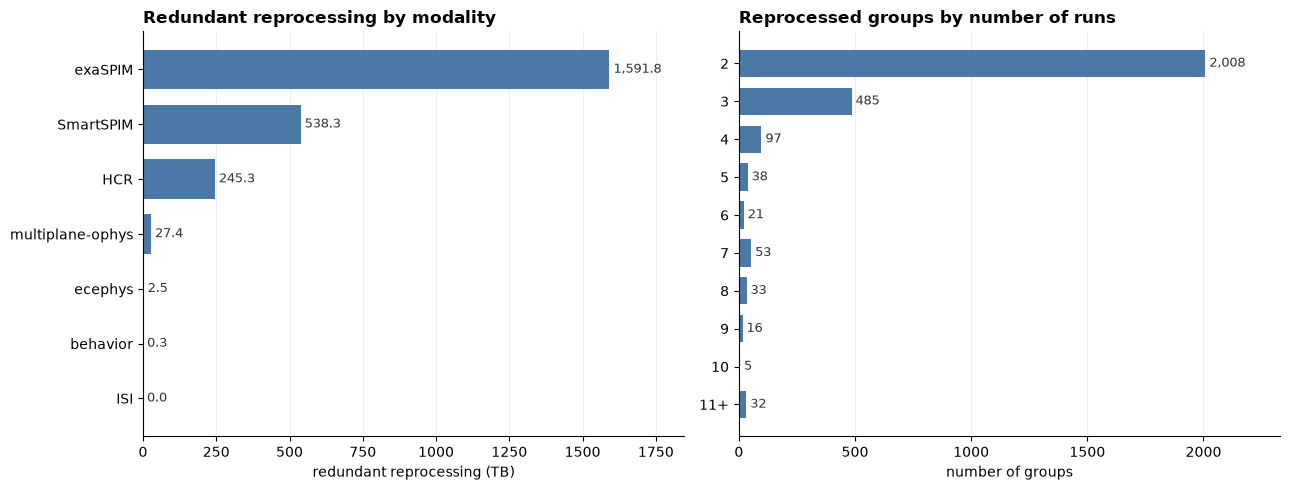

In [12]:
import matplotlib.pyplot as plt

BAR = "#4C78A8"

def _barh(ax, series, title, xlabel, valfmt="{:,.0f}"):
    s = series.iloc[::-1]                        # first item of `series` ends up on top
    ax.barh(s.index.astype(str), s.values, color=BAR, height=0.72)
    for y, v in enumerate(s.values):
        ax.text(v, y, " " + valfmt.format(v), va="center", ha="left", fontsize=9, color="#333")
    ax.set_title(title, loc="left", fontsize=12, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color="#eee"); ax.set_axisbelow(True); ax.margins(x=0.16)

# Left: redundant reprocessing (TB) by modality, excluding the unlabeled bucket.
by_mod = s3.reclaimable_by(rep, "modality", top_n=None)["reclaimable_tb"]
by_mod = by_mod[by_mod.index != "(unlabeled)"].head(10)

# Right: reprocessed (raw asset, process) groups by number of runs (2 ... 10, 11+).
dist = s3.rerun_distribution(rep)["n_groups"]
reproc = dist[dist.index >= 2]
bars = reproc[reproc.index <= 10]
runs = pd.Series(list(bars.values) + [int(reproc[reproc.index >= 11].sum())],
                 index=[str(i) for i in bars.index] + ["11+"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
_barh(axes[0], by_mod, "Redundant reprocessing by modality",
      "redundant reprocessing (TB)", valfmt="{:,.1f}")
_barh(axes[1], runs, "Reprocessed groups by number of runs", "number of groups")
fig.tight_layout(); plt.show()

### Top cleanup targets

Individual `(raw asset, process)` pairs holding the most reclaimable space, most of the savings sits in a few dozen big light-sheet assets reprocessed many times.

In [13]:
s3.top_offenders(rep, top_n=15)

,input,process_norm,reclaimable_tb,runs
0,exaSPIM_784896_2025-08-19_10-48-12,processed,102.38,14
1,exaSPIM_794492_2026-01-09_16-50-40,processed,92.87,6
2,exaSPIM_721332_2025-04-05_14-48-36,flatfield-correction_fusion,67.40,3
3,exaSPIM_794491_2025-10-21_12-31-25,processed,67.14,3
4,exaSPIM_660525_2025-12-12_18-53-11,processed,63.12,2
5,exaSPIM_794495_2026-01-21_14-25-07,processed,61.04,3
6,exaSPIM_784802_2025-09-10_17-08-56,processed,58.11,15
7,exaSPIM_784666_2025-07-25_17-36-18,processed,54.38,6
8,HCR_831990_2026-05-11_00-00-00,processed,52.85,10
9,exaSPIM_718168_2025-03-18_15-31-16,flatfield-correction_fusion,50.81,2


## Representative reprocessed assets

Fifteen raw assets in **aind-open-data** that were reprocessed multiple times, spread across modalities for variety (largest reprocessed group per modality first, then round-robin). Each table lists every asset under that raw stem: `name`, `size_tb`, and `level`, with the raw row first and the derived runs in date order. `s3.runs_for_input(df, "<raw stem>")` returns the same for any asset.

In [14]:
from IPython.display import display, Markdown

# 15 reprocessed raw assets in aind-open-data, spread across modalities for variety.
# rep = reprocessing_table(df) is aind-open-data only, so every pick is in that bucket.
cand = (rep[rep["reclaimable"]]
        .groupby(["input", "modality"], as_index=False)["size_tb"].sum())
cand["rank_in_mod"] = cand.sort_values("size_tb", ascending=False).groupby("modality").cumcount()
stems = (cand.sort_values(["rank_in_mod", "size_tb"], ascending=[True, False])
         .head(15)["input"].tolist())

for stem in stems:
    t = s3.runs_for_input(df, stem)   # raw row first, then derived by processing date
    display(Markdown(f"**{stem}** &mdash; {len(t)} assets, {t['size_tb'].sum():,.1f} TB total"))
    display(t)

**exaSPIM_784896_2025-08-19_10-48-12** &mdash; 17 assets, 204.5 TB total

,name,size_tb,level,bucket
0,exaSPIM_784896_2025-08-19_10-48-12,0.00,raw,aind-open-data
1,exaSPIM_784896_2025-08-19_10-48-12_processed_2025-08-26_12-28-02,63.16,derived,aind-open-data
2,exaSPIM_784896_2025-08-19_10-48-12_processed_2025-09-16_10-26-11,36.84,derived,aind-open-data
3,exaSPIM_784896_2025-08-19_10-48-12_processed_2025-09-18_18-30-07,0.55,derived,aind-open-data
4,exaSPIM_784896_2025-08-19_10-48-12_processed_2025-09-22_15-05-12,0.18,derived,aind-open-data
5,exaSPIM_784896_2025-08-19_10-48-12_processed_2025-09-25_09-50-33,0.22,derived,aind-open-data
6,exaSPIM_784896_2025-08-19_10-48-12_processed_2025-09-25_17-37-03,0.23,derived,aind-open-data
7,exaSPIM_784896_2025-08-19_10-48-12_processed_2025-09-25_19-15-27,0.22,derived,aind-open-data
8,exaSPIM_784896_2025-08-19_10-48-12_processed_2025-09-25_21-11-04,0.23,derived,aind-open-data
9,exaSPIM_784896_2025-08-19_10-48-12_processed_2025-09-26_07-44-54,0.11,derived,aind-open-data


**HCR_831990_2026-05-11_00-00-00** &mdash; 11 assets, 64.3 TB total

,name,size_tb,level,bucket
0,HCR_831990_2026-05-11_00-00-00,5.78,raw,aind-open-data
1,HCR_831990_2026-05-11_00-00-00_processed_2026-05-22_01-24-33,5.66,derived,aind-open-data
2,HCR_831990_2026-05-11_00-00-00_processed_2026-05-23_04-19-42,5.66,derived,aind-open-data
3,HCR_831990_2026-05-11_00-00-00_processed_2026-05-25_00-19-35,5.66,derived,aind-open-data
4,HCR_831990_2026-05-11_00-00-00_processed_2026-05-26_04-42-29,5.66,derived,aind-open-data
5,HCR_831990_2026-05-11_00-00-00_processed_2026-05-26_20-09-06,4.61,derived,aind-open-data
6,HCR_831990_2026-05-11_00-00-00_processed_2026-05-26_20-50-38,5.63,derived,aind-open-data
7,HCR_831990_2026-05-11_00-00-00_processed_2026-06-11_07-31-23,13.98,derived,aind-open-data
8,HCR_831990_2026-05-11_00-00-00_processed_2026-06-18_07-55-21,0.33,derived,aind-open-data
9,HCR_831990_2026-05-11_00-00-00_processed_2026-06-18_08-14-14,5.66,derived,aind-open-data


**828408_2025-11-19_14-19-09** &mdash; 5 assets, 6.9 TB total

...

,name,size_tb,level,bucket
0,multiplane-ophys_849375_2026-06-20_13-13-04,0.22,raw,aind-open-data
1,multiplane-ophys_849375_2026-06-20_13-13-04_processed_2026-06-21_00-47-16,0.00,derived,aind-open-data
2,multiplane-ophys_849375_2026-06-20_13-13-04_processed_2026-06-21_06-59-09,0.63,derived,aind-open-data
3,multiplane-ophys_849375_2026-06-20_13-13-04_processed_2026-06-23_17-00-47,0.00,derived,aind-open-data


**ecephys_820459_2025-11-10_15-07-13** &mdash; 8 assets, 0.4 TB total

,name,size_tb,level,bucket
0,ecephys_820459_2025-11-10_15-07-13,0.25,raw,aind-open-data
1,ecephys_820459_2025-11-10_15-07-13_sorted_2025-11-22_08-46-30,0.04,derived,aind-open-data
2,ecephys_820459_2025-11-10_15-07-13_nwb_2025-11-25_01-25-01,0.01,derived,aind-open-data
3,ecephys_820459_2025-11-10_15-07-13_sorted_2026-04-25_03-26-39,0.04,derived,aind-open-data
4,ecephys_820459_2025-11-10_15-07-13_sorted_2026-04-30_09-20-56,0.04,derived,aind-open-data
5,ecephys_820459_2025-11-10_15-07-13_nwb_2026-06-23_12-29-11,0.01,derived,aind-open-data
6,ecephys_820459_2025-11-10_15-07-13_nwb_2026-06-26_13-37-58,0.01,derived,aind-open-data
7,ecephys_820459_2025-11-10_15-07-13_sorted_2026-06-27_11-27-43,0.04,derived,aind-open-data


**behavior_751766_2025-02-15_12-08-11** &mdash; 3 assets, 0.0 TB total

,name,size_tb,level,bucket
0,behavior_751766_2025-02-15_12-08-11_videoprocessed_2025-09-09_18-59-42,0.01,derived,aind-open-data
1,behavior_751766_2025-02-15_12-08-11_sorted-opto-bp_2025-10-22_03-36-09,0.00,derived,aind-open-data
2,behavior_751766_2025-02-15_12-08-11_videoprocessed_2025-10-28_23-21-23,0.01,derived,aind-open-data
